# Лабораторна робота №4
## Трансформери та Hugging Face

### Мета роботи
Опанувати принципи побудови та навчання трансформерних моделей для машинного перекладу, а також використання готових моделей Hugging Face для роботи з текстами й зображеннями.

У роботі розглянуто:
1. Машинний переклад з англійської на українську на основі власної encoder-decoder моделі Transformer.
2. Zero-shot classification, summarization, translation та fine-tuning DistilBERT.
3. Генерацію зображення через Diffusers та порівняння зображень за ознаками DINOv2.


In [23]:
%pip install -q -U "transformers==5.24.0" "datasets==5.2.0" "diffusers==0.43.0" accelerate sentencepiece sacremoses kagglehub huggingface_hub


In [24]:
import re
import math
import gc
import time
import random
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


# 1. Машинний переклад: Transformer from scratch

Навчальний корпус: [turuta/Multi30k-uk](https://huggingface.co/datasets/turuta/Multi30k-uk), англо-українські описи зображень. Для незалежної перевірки використовується розділ `test_2016_flickr` набору [Multi30k-ukTest](https://huggingface.co/datasets/YanaDaniiel/Multi30k-ukTest).

У моделі окремо реалізовано positional encoding, multi-head attention, encoder, decoder і causal mask. Готові ваги та `nn.Transformer` не використовуються. Навчальна й валідаційна вибірки формуються тільки з `train.json`; тестові приклади не беруть участі в навчанні.


In [25]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download

EN_RE = re.compile(r"[A-Za-z]+(?:['’][A-Za-z]+)?|\d+|[.,!?;:]")
UK_RE = re.compile(r"[А-Яа-яІіЇїЄєҐґ]+(?:['’][А-Яа-яІіЇїЄєҐґ]+)?|\d+|[.,!?;:]")

def tokenize_en(text):
    return EN_RE.findall(str(text).lower())

def tokenize_uk(text):
    return UK_RE.findall(str(text).lower())

train_file = hf_hub_download(
    repo_id="turuta/Multi30k-uk",
    filename="train.json",
    repo_type="dataset"
)
train_data = load_dataset("json", data_files={"train": train_file}, split="train")

try:
    test_data = load_dataset("YanaDaniiel/Multi30k-ukTest", split="test_2016_flickr")
    test_origin = "YanaDaniiel/Multi30k-ukTest: test_2016_flickr"
except Exception as exc:
    print("Тестовий репозиторій недоступний:", str(exc)[:180])
    test_file = hf_hub_download(
        repo_id="turuta/Multi30k-uk",
        filename="test_2016_flickr.json",
        repo_type="dataset"
    )
    test_data = load_dataset("json", data_files={"test": test_file}, split="test")
    test_origin = "turuta/Multi30k-uk: test_2016_flickr.json"

MAX_WORDS = 30

def make_pairs(rows):
    selected = []
    for row in rows:
        en, uk = str(row["en"]).strip(), str(row["uk"]).strip()
        n_en, n_uk = len(tokenize_en(en)), len(tokenize_uk(uk))
        if 2 <= n_en <= MAX_WORDS and 2 <= n_uk <= MAX_WORDS:
            selected.append((en, uk))
    return selected

pairs = make_pairs(train_data)
external_test_pairs = make_pairs(test_data)
assert pairs and external_test_pairs, "Не вдалося підготувати англо-українські пари"

print("Джерело тесту:", test_origin)
print("Навчальний корпус після фільтрації:", len(pairs))
print("Незалежний тестовий корпус:", len(external_test_pairs))
for en, uk in pairs[:3]:
    print("EN:", en)
    print("UK:", uk)
    print()


train.json:   0%|          | 0.00/5.49M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

README.md:   0%|          | 0.00/7.22k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/5.58M [00:00<?, ?B/s]

test_2016_flickr.jsonl:   0%|          | 0.00/192k [00:00<?, ?B/s]

test_2017_flickr.jsonl:   0%|          | 0.00/172k [00:00<?, ?B/s]

... (4 outputs left out)

Generating test_2017_flickr split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test_2017_mscoco split:   0%|          | 0/461 [00:00<?, ? examples/s]

Generating test_2018_flickr split:   0%|          | 0/1071 [00:00<?, ? examples/s]

Джерело тесту: YanaDaniiel/Multi30k-ukTest: test_2016_flickr
Навчальний корпус після фільтрації: 28936
Незалежний тестовий корпус: 998
EN: Two young, White males are outside near many bushes.
UK: Двоє молодих білих чоловіків біля багатьох кущів.

EN: Several men in hard hats are operating a giant pulley system.
UK: Кілька чоловіків у касках керують системою гігантських блоків.

EN: A little girl climbing into a wooden playhouse.
UK: Маленька дівчинка піднімається в дерев'яний будиночок.



In [26]:
train_pairs, val_pairs = train_test_split(
    pairs,
    test_size=0.10,
    random_state=RANDOM_STATE
)
test_pairs = external_test_pairs

# Перевірка, що ідентичні речення з train не потрапили до тесту.
train_texts = {en.strip().lower() for en, _ in train_pairs}
test_pairs = [(en, uk) for en, uk in test_pairs if en.strip().lower() not in train_texts]
assert len(test_pairs) > 0, "Усі тестові речення перетинаються з навчальними"

print("Train:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Test:", len(test_pairs))


Train: 26042
Validation: 2894
Test: 998


In [27]:
SPECIALS = ["<PAD>", "<UNK>", "<BOS>", "<EOS>"]
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
MAX_LEN = 34

def build_vocab(texts, tokenizer, max_size=11000, min_freq=2):
    counter = Counter()
    for text in texts:
        counter.update(tokenizer(text))
    vocab = {token: i for i, token in enumerate(SPECIALS)}
    for token, freq in counter.most_common():
        if freq < min_freq or len(vocab) >= max_size:
            break
        if token not in vocab:
            vocab[token] = len(vocab)
    return vocab

en_vocab = build_vocab([x[0] for x in train_pairs], tokenize_en)
uk_vocab = build_vocab([x[1] for x in train_pairs], tokenize_uk)
uk_idx_to_token = {i: t for t, i in uk_vocab.items()}

print("EN vocab:", len(en_vocab))
print("UK vocab:", len(uk_vocab))


EN vocab: 5646
UK vocab: 9526


In [28]:
def encode(text, vocab, tokenizer, max_len=MAX_LEN):
    ids = [BOS_IDX] + [vocab.get(t, UNK_IDX) for t in tokenizer(text)] + [EOS_IDX]
    ids = ids[:max_len]
    if ids[-1] != EOS_IDX:
        ids[-1] = EOS_IDX
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids

class TranslationDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, idx):
        en, uk = self.pairs[idx]
        src = torch.tensor(encode(en, en_vocab, tokenize_en), dtype=torch.long)
        tgt = torch.tensor(encode(uk, uk_vocab, tokenize_uk), dtype=torch.long)
        return src, tgt

train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=64, shuffle=True)
val_loader = DataLoader(TranslationDataset(val_pairs), batch_size=64, shuffle=False)

In [29]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=256):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.d_model = d_model
        self.wq = nn.Linear(d_model, d_model)
        self.wk = nn.Linear(d_model, d_model)
        self.wv = nn.Linear(d_model, d_model)
        self.wo = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
    def split_heads(self, x):
        b, t, _ = x.shape
        return x.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)
    def forward(self, query, key, value, mask=None):
        q = self.split_heads(self.wq(query))
        k = self.split_heads(self.wk(key))
        v = self.split_heads(self.wv(value))
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e9)
        attn = self.dropout(torch.softmax(scores, dim=-1))
        context = torch.matmul(attn, v).transpose(1, 2).contiguous()
        b, t, _, _ = context.shape
        return self.wo(context.view(b, t, self.d_model))

In [30]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model)
        )
    def forward(self, x):
        return self.net(x)

class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, src_mask):
        x = self.norm1(x + self.dropout(self.attn(x, x, x, src_mask)))
        x = self.norm2(x + self.dropout(self.ff(x)))
        return x

class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, memory, tgt_mask, src_mask):
        x = self.norm1(x + self.dropout(self.self_attn(x, x, x, tgt_mask)))
        x = self.norm2(x + self.dropout(self.cross_attn(x, memory, memory, src_mask)))
        x = self.norm3(x + self.dropout(self.ff(x)))
        return x

class ScratchTransformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model=128, n_heads=4, num_layers=2, d_ff=256, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.src_embedding = nn.Embedding(src_vocab_size, d_model, padding_idx=PAD_IDX)
        self.tgt_embedding = nn.Embedding(tgt_vocab_size, d_model, padding_idx=PAD_IDX)
        self.positional = PositionalEncoding(d_model, MAX_LEN + 10)
        self.encoder_layers = nn.ModuleList([EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(num_layers)])
        self.decoder_layers = nn.ModuleList([DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(num_layers)])
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model, tgt_vocab_size)
    def make_src_mask(self, src):
        return (src != PAD_IDX).unsqueeze(1).unsqueeze(2)
    def make_tgt_mask(self, tgt):
        seq_len = tgt.size(1)
        padding_mask = (tgt != PAD_IDX).unsqueeze(1).unsqueeze(2)
        causal_mask = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool, device=tgt.device)).unsqueeze(0).unsqueeze(0)
        return padding_mask & causal_mask
    def encode(self, src):
        src_mask = self.make_src_mask(src)
        x = self.dropout(self.positional(self.src_embedding(src) * math.sqrt(self.d_model)))
        for layer in self.encoder_layers:
            x = layer(x, src_mask)
        return x, src_mask
    def decode(self, tgt, memory, src_mask):
        tgt_mask = self.make_tgt_mask(tgt)
        x = self.dropout(self.positional(self.tgt_embedding(tgt) * math.sqrt(self.d_model)))
        for layer in self.decoder_layers:
            x = layer(x, memory, tgt_mask, src_mask)
        return self.output(x)
    def forward(self, src, tgt):
        memory, src_mask = self.encode(src)
        return self.decode(tgt, memory, src_mask)

In [31]:
transformer = ScratchTransformer(len(en_vocab), len(uk_vocab)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.AdamW(transformer.parameters(), lr=3e-4)
print("Parameters:", f"{sum(p.numel() for p in transformer.parameters()):,}")

def run_translation_epoch(model, loader, optimizer=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    losses = []
    with torch.set_grad_enabled(train_mode):
        for src, tgt in loader:
            src, tgt = src.to(device), tgt.to(device)
            tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
            if train_mode:
                optimizer.zero_grad()
            logits = model(src, tgt_in)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            losses.append(loss.item())
    return float(np.mean(losses))

Parameters: 3,833,398


In [32]:
EPOCHS = 8
history = {"train_loss": [], "val_loss": []}
best_state, best_val = None, float("inf")
start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    tr = run_translation_epoch(transformer, train_loader, optimizer)
    va = run_translation_epoch(transformer, val_loader)
    history["train_loss"].append(tr)
    history["val_loss"].append(va)
    if va < best_val:
        best_val = va
        best_state = {k: v.detach().cpu().clone() for k, v in transformer.state_dict().items()}
    print(f"Epoch {epoch}/{EPOCHS}: train={tr:.4f}, val={va:.4f}")

transformer.load_state_dict(best_state)
print(f"Training time: {(time.perf_counter()-start)/60:.2f} min")
print(f"Best validation loss: {best_val:.4f}")


Epoch 1/8: train=5.4884, val=4.4238
Epoch 2/8: train=4.3605, val=3.9289
Epoch 3/8: train=3.9468, val=3.6034
Epoch 4/8: train=3.6473, val=3.3704
Epoch 5/8: train=3.4065, val=3.1953
Epoch 6/8: train=3.2037, val=3.0413
Epoch 7/8: train=3.0302, val=2.9225
Epoch 8/8: train=2.8730, val=2.8087
Training time: 3.17 min
Best validation loss: 2.8087


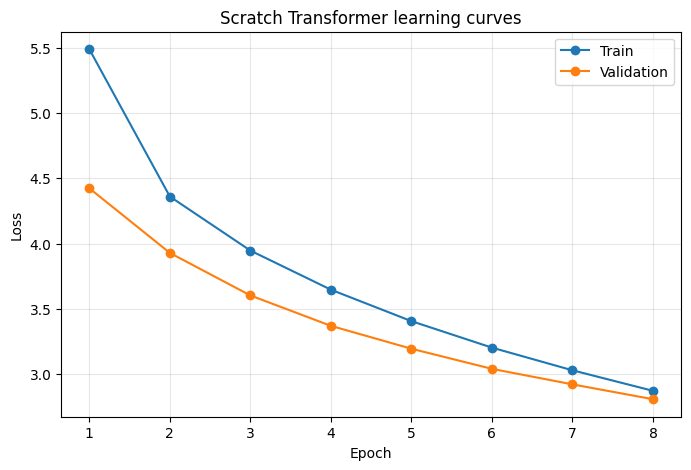

In [33]:
epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Scratch Transformer learning curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [34]:
def decode_tokens(ids):
    tokens = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_IDX:
            break
        if idx not in (PAD_IDX, BOS_IDX):
            tokens.append(uk_idx_to_token.get(idx, "<UNK>"))
    text = " ".join(tokens)
    return re.sub(r"\s+([.,!?;:])", r"\1", text)

@torch.no_grad()
def translate_sentence(sentence):
    transformer.eval()
    src = torch.tensor([encode(sentence, en_vocab, tokenize_en)], dtype=torch.long, device=device)
    memory, src_mask = transformer.encode(src)
    generated = torch.tensor([[BOS_IDX]], dtype=torch.long, device=device)
    for _ in range(MAX_LEN - 1):
        logits = transformer.decode(generated, memory, src_mask)
        next_token = logits[:, -1].argmax(dim=-1, keepdim=True)
        generated = torch.cat([generated, next_token], dim=1)
        if next_token.item() == EOS_IDX:
            break
    return decode_tokens(generated[0].cpu().tolist())

for en, uk in test_pairs[:8]:
    print("EN:    ", en)
    print("Target:", uk)
    print("Model: ", translate_sentence(en))
    print("-" * 60)


EN:     A man in an orange hat starring at something.
Target: Людина в помаранчевій капелюсі в чомусь знімається.
Model:  чоловік у помаранчевій капелюсі дивиться на щось.
------------------------------------------------------------
EN:     A Boston Terrier is running on lush green grass in front of a white fence.
Target: Бостонський тер’єр біжить по пишній зеленій траві перед білим парканом.
Model:  білий собака біжить по траві перед білим собою.
------------------------------------------------------------
EN:     A girl in karate uniform breaking a stick with a front kick.
Target: Дівчина в формі карате ламає палицю переднім ударом.
Model:  дівчина в формі танцює перед натовпом.
------------------------------------------------------------
EN:     Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.
Target: П'ятеро людей у ​​зимових куртках і шоломах стоять на снігу , на фоні снігоходи.
Model:  п'ятеро людей, одягнені в <UNK> та <UNK>, 

### Висновок до частини 1

Реалізовано encoder-decoder Transformer (3 833 398 параметрів) з навчанням на паралельних англо-українських підписах Multi30k-uk (26 042 навчальних, 2 894 валідаційних і 998 тестових пар). За 8 епох навчання (3,17 хв) функція втрат стабільно зменшилася: train loss з 5,4884 до 2,8730, validation loss з 4,4238 до 2,8087. На окремому тестовому наборі модель передає базову структуру простих речень, але на довших описах зустрічаються повтори та токени <UNK>, оскільки модель навчалася з нуля на обмеженому корпусі.


# 2. Текстові моделі Hugging Face

## 2а. Zero-shot classification, summarization, translation

Для zero-shot classification використовується мультимовна NLI-модель. Для summarization і translation використовується `text-generation` pipeline з моделлю Qwen2.5-Instruct. На GPU завантажується версія 1.5B, а без GPU - 0.5B.


In [35]:
from transformers import pipeline

In [36]:
zero_shot = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0 if torch.cuda.is_available() else -1
)

text_uk = "Компанія повідомила про нову кібератаку, яка призвела до витоку облікових даних користувачів."
labels_uk = ["кібербезпека", "спорт", "економіка", "культура"]
result = zero_shot(text_uk, labels_uk)

print(text_uk)
for label, score in zip(result["labels"], result["scores"]):
    print(f"{label}: {score:.3f}")

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (2 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Компанія повідомила про нову кібератаку, яка призвела до витоку облікових даних користувачів.
кібербезпека: 0.995
економіка: 0.003
культура: 0.002
спорт: 0.001


In [37]:
del zero_shot
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

In [38]:
text_helper = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct" if torch.cuda.is_available() else "Qwen/Qwen2.5-0.5B-Instruct",
    device=0 if torch.cuda.is_available() else -1,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

article = (
    "Кібербезпека стає дедалі важливішою для державних установ і приватних компаній. "
    "Кількість фішингових атак, атак програм-вимагачів та спроб викрадення облікових даних зростає. "
    "Організації впроваджують багатофакторну автентифікацію, EDR та моніторинг мережі. "
    "Технічних засобів недостатньо без регулярного навчання співробітників і правильної реакції на інциденти."
)

summary_messages = [
    {
        "role": "system",
        "content": (
            "Стисло резюмуй українські тексти. Напиши одне завершене речення "
            "українською мовою, не більше 35 слів, із крапкою в кінці. "
            "Не додавай вступів і пояснень."
        )
    },
    {"role": "user", "content": "Підсумуй текст:\n\n" + article}
]

summary_result = text_helper(
    summary_messages,
    max_new_tokens=180,
    do_sample=False
)
summary_text = summary_result[0]["generated_text"][-1]["content"].strip()

# Якщо генерація не завершила речення, повторюємо із більшим лімітом.
if not summary_text.endswith((".", "!", "?")):
    summary_result = text_helper(
        summary_messages,
        max_new_tokens=200,
        do_sample=False
    )
    summary_text = summary_result[0]["generated_text"][-1]["content"].strip()

print("Оригінал:\n", article)
print("\nSummary:\n", summary_text)


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Оригінал:
 Кібербезпека стає дедалі важливішою для державних установ і приватних компаній. Кількість фішингових атак, атак програм-вимагачів та спроб викрадення облікових даних зростає. Організації впроваджують багатофакторну автентифікацію, EDR та моніторинг мережі. Технічних засобів недостатньо без регулярного навчання співробітників і правильної реакції на інциденти.

Summary:
 Кібербезпека становить ключовий фактор для державних організацій та приватних компаній, оскільки фішингові атаки та спроби викрадення облікових даних зростають. Організації впроваджають багатофакторну автентифікацію, EDR та моніторинг мережі. Важливо регулярно навчати співробітників та правильно реагувати на інциденти.


In [39]:
translation_input = (
    "Система виявила підозрілу активність "
    "на робочій станції користувача."
)

translation_messages = [
    {
        "role": "system",
        "content": (
            "You are a professional translator from Ukrainian to English. "
            "Return only a fluent English translation. "
            "Do not transliterate Ukrainian words and do not add explanations."
        )
    },
    {
        "role": "user",
        "content": translation_input
    }
]

translation_result = text_helper(
    translation_messages,
    max_new_tokens=60,
    do_sample=False
)

translation_text = translation_result[0]["generated_text"][-1]["content"].strip()

print("UA:", translation_input)
print("EN:", translation_text)

UA: Система виявила підозрілу активність на робочій станції користувача.
EN: System detected suspicious activity on the user's work station.


In [40]:
del text_helper
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 2б. Fine-tuning DistilBERT на датасеті з лабораторної №2

Для класифікації використано `phishing_email_sample_10000.csv` з попередньої лабораторної роботи. Корпус Multi30k призначений для перекладу та не має міток phishing/legitimate, тому тут застосовується окремий датасет. Збережено очищення тексту, `random_state=42`, тестову вибірку та метрики з лабораторної №2. Базовий метод TF-IDF + Logistic Regression перераховується на цій самій вибірці.


In [41]:
PHISH_LOCAL = Path("phishing_email_sample_10000.csv")
PHISH_URL = "https://raw.githubusercontent.com/maksymenkokyrylofb61mp/IAD-Lab2-CLaMP/main/phishing_email_sample_10000.csv"
text_df = pd.read_csv(PHISH_LOCAL if PHISH_LOCAL.exists() else PHISH_URL)
text_df = text_df.dropna(subset=["text_combined", "label"]).copy()
print(text_df.shape)
print(text_df["label"].value_counts())

(10000, 2)
label
1    5000
0    5000
Name: count, dtype: int64


In [42]:
stop_words = set(ENGLISH_STOP_WORDS)
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(w for w in text.split() if w not in stop_words and len(w) > 2)

text_df["clean_text"] = text_df["text_combined"].apply(clean_text)
text_df = text_df[text_df["clean_text"].str.len() > 0].reset_index(drop=True)
train_df, test_df = train_test_split(
    text_df, test_size=0.20, random_state=RANDOM_STATE, stratify=text_df["label"]
)
print("Train:", train_df.shape, "Test:", test_df.shape)

Train: (7999, 3) Test: (2000, 3)


In [43]:
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2, max_df=0.95)
X_train = tfidf.fit_transform(train_df["clean_text"])
X_test = tfidf.transform(test_df["clean_text"])

baseline_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline_model.fit(X_train, train_df["label"])
baseline_pred = baseline_model.predict(X_test)

base_acc = accuracy_score(test_df["label"], baseline_pred)
base_p, base_r, base_f1, _ = precision_recall_fscore_support(
    test_df["label"], baseline_pred, average="binary"
)
print(f"Baseline Accuracy={base_acc:.4f}, Precision={base_p:.4f}, Recall={base_r:.4f}, F1={base_f1:.4f}")

Baseline Accuracy=0.9695, Precision=0.9662, Recall=0.9730, F1=0.9696


In [44]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

MAX_BERT_LEN = 256
train_enc = tokenizer(train_df["clean_text"].tolist(), padding="max_length", truncation=True, max_length=MAX_BERT_LEN, return_tensors="pt")
test_enc = tokenizer(test_df["clean_text"].tolist(), padding="max_length", truncation=True, max_length=MAX_BERT_LEN, return_tensors="pt")

train_ds = TensorDataset(train_enc["input_ids"], train_enc["attention_mask"], torch.tensor(train_df["label"].values, dtype=torch.long))
test_ds = TensorDataset(test_enc["input_ids"], test_enc["attention_mask"], torch.tensor(test_df["label"].values, dtype=torch.long))
train_loader_bert = DataLoader(train_ds, batch_size=16, shuffle=True)
test_loader_bert = DataLoader(test_ds, batch_size=32, shuffle=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [45]:
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)
BERT_EPOCHS = 2
bert_losses = []
start = time.perf_counter()

for epoch in range(1, BERT_EPOCHS + 1):
    bert_model.train()
    total_loss = 0.0
    for input_ids, attention_mask, labels in train_loader_bert:
        input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        outputs.loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        optimizer.step()
        total_loss += outputs.loss.item()
    avg_loss = total_loss / len(train_loader_bert)
    bert_losses.append(avg_loss)
    print(f"Epoch {epoch}/{BERT_EPOCHS}: train loss={avg_loss:.4f}")

print(f"Fine-tuning time: {(time.perf_counter()-start)/60:.2f} min")

Epoch 1/2: train loss=0.1818
Epoch 2/2: train loss=0.0583
Fine-tuning time: 6.29 min


In [46]:
bert_model.eval()
bert_preds, bert_targets = [], []
with torch.no_grad():
    for input_ids, attention_mask, labels in test_loader_bert:
        outputs = bert_model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device))
        bert_preds.extend(outputs.logits.argmax(dim=1).cpu().numpy())
        bert_targets.extend(labels.numpy())

bert_acc = accuracy_score(bert_targets, bert_preds)
bert_p, bert_r, bert_f1, _ = precision_recall_fscore_support(bert_targets, bert_preds, average="binary")
print(classification_report(bert_targets, bert_preds, target_names=["Legitimate", "Phishing"]))

comparison = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "Fine-tuned DistilBERT"],
    "Accuracy": [base_acc, bert_acc],
    "Precision": [base_p, bert_p],
    "Recall": [base_r, bert_r],
    "F1": [base_f1, bert_f1]
})
comparison

              precision    recall  f1-score   support

  Legitimate       0.95      0.99      0.97      1000
    Phishing       0.99      0.95      0.97      1000

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



,Model,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,0.9695,0.966236,0.973,0.969606
1,Fine-tuned DistilBERT,0.9700,0.992662,0.947,0.969294


### Висновок до fine-tuning

На тестовій вибірці з лабораторної №2 (2000 листів) метод TF-IDF + Logistic Regression отримав Accuracy 96,95%, Precision 96,62%, Recall 97,30% і F1 0,9696. Після двох епох донавчання DistilBERT показав Accuracy 97,00% (+0,05 відсоткового пункту) та суттєво вищий Precision 99,27%, однак нижчий Recall 94,70%, через що F1 склав 0,9693. Порівняння виконано на однаковій тестовій вибірці: DistilBERT мінімізує хибні спрацьовування на легітимних листах, тоді як TF-IDF + Logistic Regression за дві епохи без додаткового підбору порога класифікації дає трохи вищу повноту.

# 3. Робота із зображеннями

## 3а. Генерація зображення за текстовим запитом (Diffusers)


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Prompt: Photorealistic cybersecurity operations center with three analysts sitting at desks, computer monitors showing security dashboards, wide angle view, soft blue lighting, detailed modern office, sharp focus, professional photography


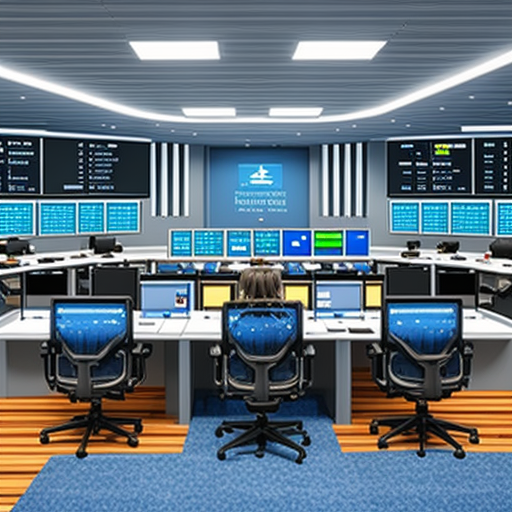

In [47]:
from diffusers import AutoPipelineForText2Image
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor

if not torch.cuda.is_available():
    print("Для генерації зображення потрібен GPU у середовищі Colab.")
else:
    safety_checker = StableDiffusionSafetyChecker.from_pretrained(
        "CompVis/stable-diffusion-safety-checker",
        torch_dtype=torch.float16
    )
    feature_extractor = CLIPImageProcessor.from_pretrained(
        "CompVis/stable-diffusion-safety-checker"
    )
    image_pipe = AutoPipelineForText2Image.from_pretrained(
        "stabilityai/sd-turbo",
        torch_dtype=torch.float16,
        variant="fp16",
        safety_checker=safety_checker,
        feature_extractor=feature_extractor
    ).to("cuda")

    prompt = (
        "Photorealistic cybersecurity operations center with three analysts sitting at desks, "
        "computer monitors showing security dashboards, wide angle view, soft blue lighting, "
        "detailed modern office, sharp focus, professional photography"
    )
    generated_image = image_pipe(
        prompt=prompt,
        num_inference_steps=4,
        guidance_scale=0.0,
        height=512,
        width=512,
        generator=torch.Generator(device="cuda").manual_seed(RANDOM_STATE)
    ).images[0]
    print("Prompt:", prompt)
    display(generated_image)


In [48]:
for name in ("image_pipe", "safety_checker", "feature_extractor"):
    if name in globals():
        del globals()[name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


## 3б. DINOv2: порівняння 10 зображень

Використовується вибірка із набору malware/benign images, як у попередній роботі. Для кожного зображення обчислюється 768-вимірний вектор DINOv2 та його L2-нормована версія. Після цього визначаються попарні евклідові відстані між різними зображеннями.


In [49]:
import kagglehub

IMAGE_DATASET_HANDLE = "bishwajitprasadgond/malware-benign-image-sample"
image_dataset_dir = Path(kagglehub.dataset_download(IMAGE_DATASET_HANDLE))
all_image_paths = sorted(
    list(image_dataset_dir.rglob("*.png")) + list(image_dataset_dir.rglob("*.jpg")) + list(image_dataset_dir.rglob("*.jpeg"))
)
print("Images:", len(all_image_paths))

def image_class(path):
    label = path.stem.lower().split("_")[0]
    return "worm" if label == "worms" else label

by_class = {}
for p in all_image_paths:
    by_class.setdefault(image_class(p), []).append(p)

classes = sorted(by_class)
selected_paths = [by_class[c][0] for c in classes]
extra = 1
while len(selected_paths) < 10:
    for c in classes:
        if extra < len(by_class[c]) and len(selected_paths) < 10:
            selected_paths.append(by_class[c][extra])
    extra += 1
selected_paths = selected_paths[:10]
print([image_class(p) for p in selected_paths])

Images: 22056
['adware', 'backdoor', 'benign', 'downloader', 'spyware', 'trojan', 'virus', 'worm', 'adware', 'backdoor']


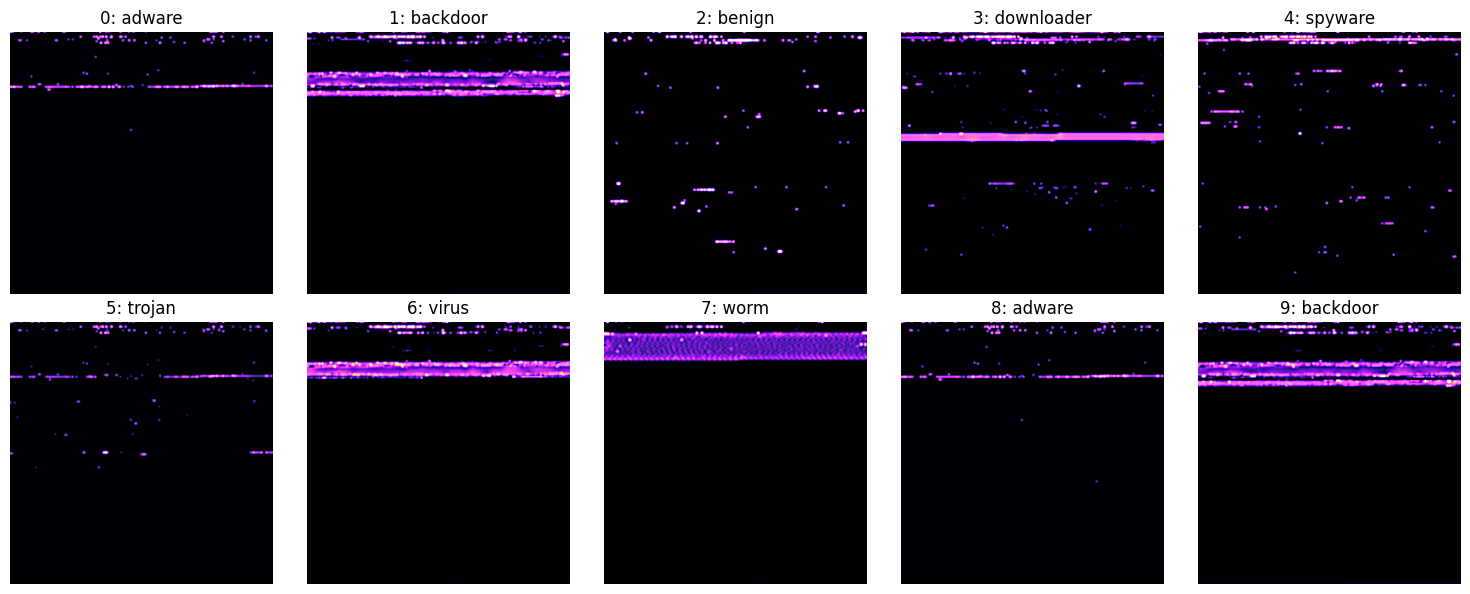

In [50]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (ax, path) in enumerate(zip(axes.ravel(), selected_paths)):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{i}: {image_class(path)}")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [51]:
from transformers import AutoImageProcessor, AutoModel

DINO_MODEL = "facebook/dinov2-base"
processor = AutoImageProcessor.from_pretrained(DINO_MODEL)
dino = AutoModel.from_pretrained(DINO_MODEL).to(device)
dino.eval()

images = [Image.open(p).convert("RGB") for p in selected_paths]
inputs = processor(images=images, return_tensors="pt")
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = dino(**inputs)

features = outputs.last_hidden_state[:, 0, :]
features_norm = F.normalize(features, p=2, dim=1)
print("Feature matrix:", features_norm.shape)
print("L2 norms:", torch.norm(features_norm, dim=1).cpu().numpy())

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Feature matrix: torch.Size([10, 768])
L2 norms: [1.         0.99999994 1.         1.         1.         1.
 1.         0.99999994 1.         0.99999994]


Найближча пара: (1, 9, 0.08863122761249542) backdoor backdoor
Найвіддаленіша пара: (2, 7, 1.1502147912979126) benign worm


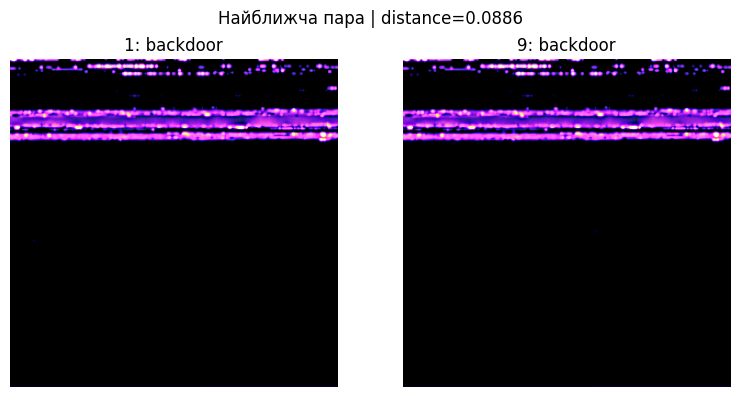

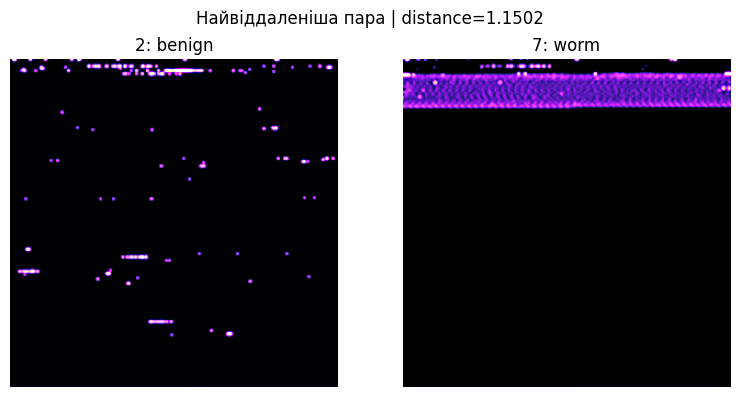

In [52]:
distance_matrix = torch.cdist(features_norm, features_norm, p=2).cpu().numpy()
pairs = [(i, j, float(distance_matrix[i, j])) for i, j in combinations(range(10), 2)]
pairs = sorted(pairs, key=lambda x: x[2])
nearest, farthest = pairs[0], pairs[-1]

print("Найближча пара:", nearest, image_class(selected_paths[nearest[0]]), image_class(selected_paths[nearest[1]]))
print("Найвіддаленіша пара:", farthest, image_class(selected_paths[farthest[0]]), image_class(selected_paths[farthest[1]]))

def show_pair(pair, title):
    i, j, dist = pair
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    for ax, idx in zip(axes, [i, j]):
        ax.imshow(Image.open(selected_paths[idx]).convert("RGB"))
        ax.set_title(f"{idx}: {image_class(selected_paths[idx])}")
        ax.axis("off")
    fig.suptitle(f"{title} | distance={dist:.4f}")
    plt.tight_layout(); plt.show()

show_pair(nearest, "Найближча пара")
show_pair(farthest, "Найвіддаленіша пара")

# Загальний висновок

1. У частині 1 реалізовано Transformer encoder-decoder без використання готової архітектури. Модель навчалася 8 епох на датасеті Multi30k-uk (validation loss знизився з 4,4238 до 2,8087), а якість її перекладів перевірено на окремому тестовому наборі.
2. У частині 2 виконано zero-shot classification, summarization і translation через Hugging Face pipeline. Для класифікації електронних листів донавчання DistilBERT за 2 епохи забезпечило Accuracy 97,00% і F1 0,9693 (проти 96,95% і 0,9696 у TF-IDF + Logistic Regression) із помітно вищим Precision (99,27% проти 96,62%) при нижчому Recall (94,70% проти 97,30%).
3. У частині 3 згенеровано зображення за текстовим описом (SD-Turbo) і порівняно 10 зображень на основі 768-вимірних L2-нормованих ознак DINOv2. Найближчими за ознаками були два зображення класу backdoor (відстань 0,0886), а найвіддаленішими - benign та worm (1,1502), що узгоджується з їхньою візуальною відмінністю.

Найкращі прикладні результати в цій роботі отримано з попередньо навченими моделями. Власний Transformer демонструє принцип побудови та навчання архітектури, але для точнішого перекладу потребує більшої кількості епох, ширшого словника або субслівної токенізації.